# Car Price Prediction (MSRP)

**Goal:** predict a car's MSRP (list price) from its features: make, year, engine power, fuel economy, body style, etc.

**Dataset:** *Car Features and MSRP* (Kaggle). Put `data_car_price.csv` in the same folder as this notebook.

**Approach**
1. Clean the data and explore it (EDA).
2. Split into train / validation / test (60 / 20 / 20).
3. Build features with a reusable transformer that learns everything **from the training set only** (no data leakage).
4. Baseline: linear regression with regularization, written from scratch with NumPy.
5. Compare against scikit-learn models (Ridge, Random Forest, Gradient Boosting) using validation and 5-fold cross-validation.
6. Evaluate the best model once on the test set, analyse its errors, and save it for deployment.

The target is modelled as `log(MSRP + 1)` because prices have a long right tail.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 1. Load and clean the data

In [2]:
def clean(df):
    """Lowercase column names and text values, and replace spaces with underscores."""
    df = df.copy()
    df.columns = df.columns.str.lower().str.replace(' ', '_')
    text_cols = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
    for col in text_cols:
        df[col] = df[col].str.lower().str.replace(' ', '_')
    return df


cars = clean(pd.read_csv('data_car_price.csv'))
print(cars.shape)
cars.head()

(11914, 16)


,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,bmw,1_series_m,2011,premium_unleaded_(required),335.0,6.0,manual,rear_wheel_drive,2.0,"factory_tuner,luxury,high-performance",compact,coupe,26,19,3916,46135
1,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,convertible,28,19,3916,40650
2,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,high-performance",compact,coupe,28,20,3916,36350
3,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,coupe,28,18,3916,29450
4,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,luxury,compact,convertible,28,18,3916,34500


**Duplicates.** If the same row appears twice, one copy can land in train and the other in test, so the model is "tested" on something it has already seen and the score looks better than it really is. We drop duplicates before splitting.

In [4]:
print('Duplicate rows:', cars.duplicated().sum())
cars = cars.drop_duplicates().reset_index(drop=True)
print('Rows after dropping duplicates:', len(cars))

Duplicate rows: 715
Rows after dropping duplicates: 11199


## 2. Exploratory data analysis

In [5]:
cars.msrp.describe()

count    1.119900e+04
mean     4.192593e+04
std      6.153505e+04
min      2.000000e+03
25%      2.159950e+04
50%      3.067500e+04
75%      4.303250e+04
max      2.065902e+06
Name: msrp, dtype: float64

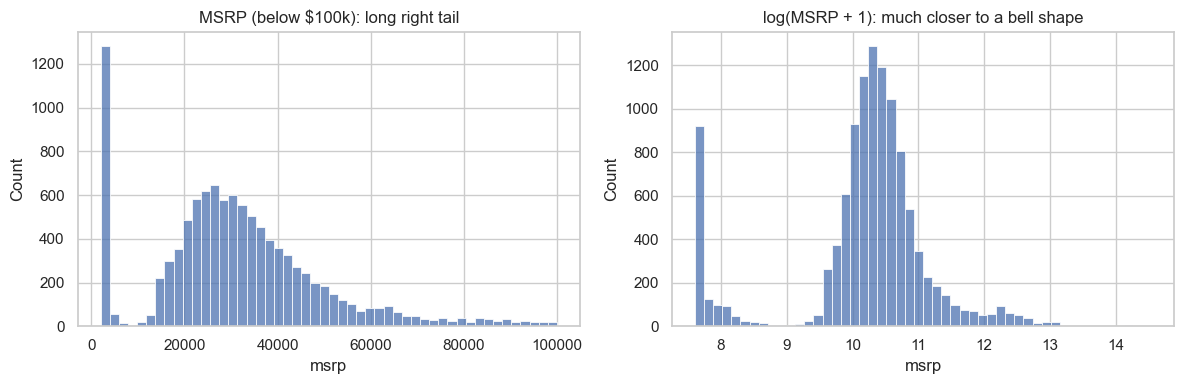

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(cars.msrp[cars.msrp < 100_000], bins=50, ax=axes[0])
axes[0].set_title('MSRP (below $100k): long right tail')

sns.histplot(np.log1p(cars.msrp), bins=50, ax=axes[1])
axes[1].set_title('log(MSRP + 1): much closer to a bell shape')

plt.tight_layout()
plt.show()

In [7]:
missing = cars.isnull().sum()
missing[missing > 0].sort_values(ascending=False)

market_category     3376
engine_hp             69
engine_cylinders      30
number_of_doors        6
engine_fuel_type       3
dtype: int64

Missing values are **not** filled here. They are filled inside the feature transformer (section 4) using statistics from the training set only.

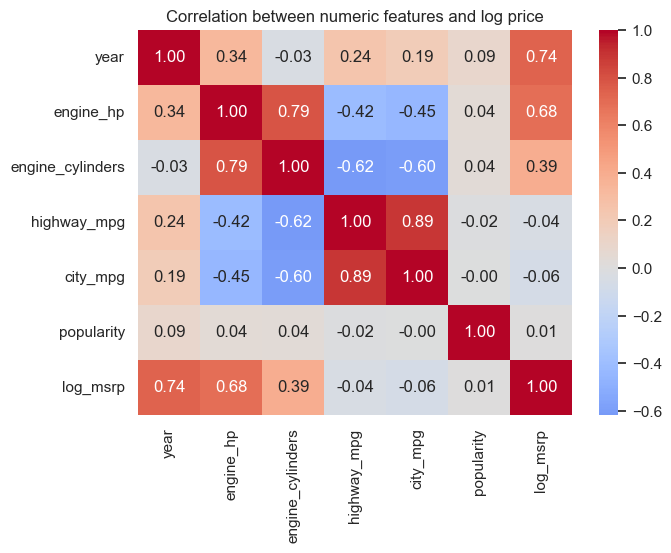

In [8]:
num_cols = ['year', 'engine_hp', 'engine_cylinders', 'highway_mpg', 'city_mpg', 'popularity']
corr = cars[num_cols].assign(log_msrp=np.log1p(cars.msrp)).corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation between numeric features and log price')
plt.show()

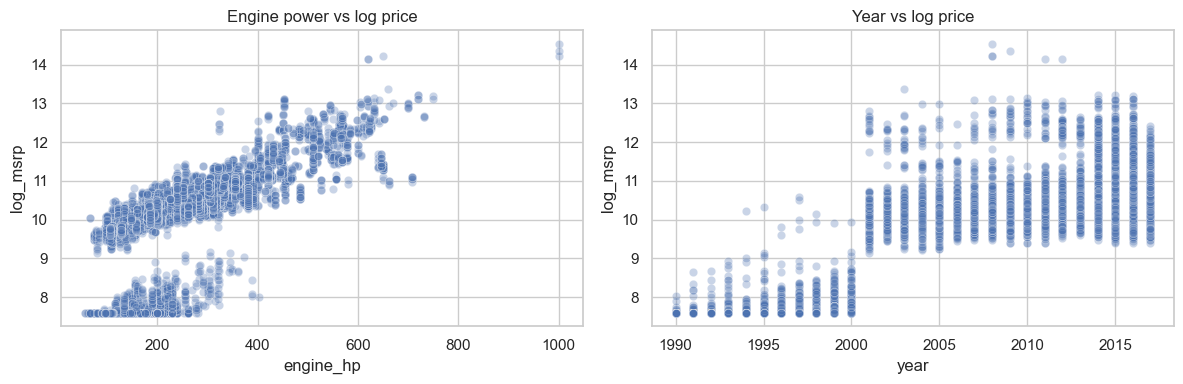

In [9]:
plot_df = cars.assign(log_msrp=np.log1p(cars.msrp))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=plot_df, x='engine_hp', y='log_msrp', alpha=0.3, ax=axes[0])
axes[0].set_title('Engine power vs log price')
sns.scatterplot(data=plot_df, x='year', y='log_msrp', alpha=0.3, ax=axes[1])
axes[1].set_title('Year vs log price')
plt.tight_layout()
plt.show()

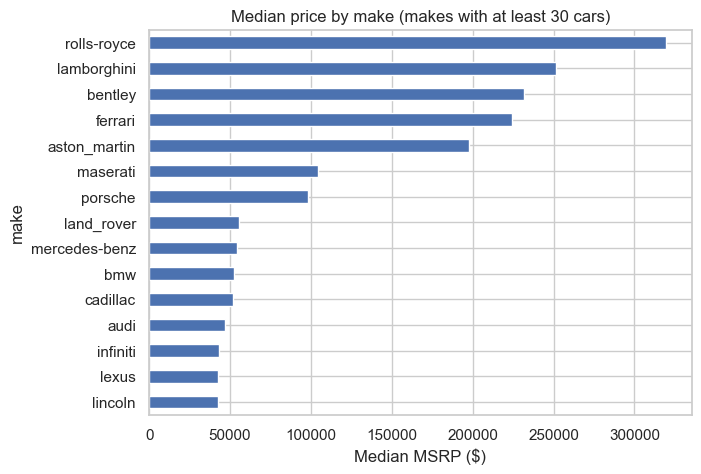

In [10]:
by_make = (cars.groupby('make').msrp.agg(['median', 'count'])
                .query('count >= 30')
                .sort_values('median', ascending=False)
                .head(15))

ax = by_make['median'].plot.barh(figsize=(7, 5))
ax.invert_yaxis()
ax.set_xlabel('Median MSRP ($)')
ax.set_title('Median price by make (makes with at least 30 cars)')
plt.show()

## 3. Train / validation / test split

* **Train (60%)**: fit the models.
* **Validation (20%)**: compare models and tune settings.
* **Test (20%)**: touched **once**, at the very end, to estimate real-world performance.

In [11]:
cars['log_msrp'] = np.log1p(cars['msrp'])

train_val, test = train_test_split(cars, test_size=0.2, random_state=RANDOM_STATE)
train, val = train_test_split(train_val, test_size=0.25, random_state=RANDOM_STATE)  # 0.25 * 0.8 = 0.2

print(len(train), len(val), len(test))

target_cols = ['msrp', 'log_msrp']
X_train, X_val, X_test = (d.drop(columns=target_cols) for d in (train, val, test))
y_train, y_val, y_test = train.log_msrp.values, val.log_msrp.values, test.log_msrp.values

6719 2240 2240


## 4. Feature engineering (leakage-free)

`CarFeatures` turns raw rows into a numeric table:

* numeric columns: missing values filled with the **median of the training set** (filling with 0 would mean "a car with 0 horsepower");
* `age = reference_year - year`, where the reference year is the newest year in the training set;
* one-hot columns for the number of doors;
* one-hot columns for the **5 most frequent values** of each categorical column (rare values are ignored).

Everything that is *learned from data* (medians, reference year, frequent categories) is learned in `fit()` from the training rows only. Because it follows the scikit-learn API it can be placed inside a `Pipeline`, so cross-validation re-learns it on every fold, and the same object can be saved and used for new cars.

In [12]:
NUMERIC = ['engine_hp', 'engine_cylinders', 'highway_mpg', 'city_mpg', 'popularity']
CATEGORICAL = ['make', 'engine_fuel_type', 'transmission_type', 'driven_wheels',
               'market_category', 'vehicle_size', 'vehicle_style']
DOOR_VALUES = [2, 3, 4]


class CarFeatures(BaseEstimator, TransformerMixin):
    """Turn raw car rows into a numeric feature table.

    Medians, the reference year and the most frequent categories are learned
    in fit() from the data it is given (the training rows) and re-used as-is
    in transform(), so validation / test rows never influence them.
    """

    def __init__(self, top_n=5):
        self.top_n = top_n

    def fit(self, X, y=None):
        self.medians_ = X[NUMERIC].median()
        self.reference_year_ = int(X['year'].max())
        self.categories_ = {c: list(X[c].value_counts().head(self.top_n).index)
                            for c in CATEGORICAL}
        return self

    def transform(self, X):
        X = X.copy()
        X[NUMERIC] = X[NUMERIC].fillna(self.medians_)
        features = list(NUMERIC)

        X['age'] = self.reference_year_ - X['year']
        features.append('age')

        for v in DOOR_VALUES:
            col = f'num_doors_{v}'
            X[col] = (X['number_of_doors'] == v).astype(int)
            features.append(col)

        for c, values in self.categories_.items():
            for v in values:
                col = f'{c}_{v}'
                X[col] = (X[c] == v).astype(int)
                features.append(col)

        return X[features]

In [13]:
feats = CarFeatures().fit(X_train)
X_train_num = feats.transform(X_train)
print(X_train_num.shape)
X_train_num.head()

(6719, 41)


,engine_hp,engine_cylinders,highway_mpg,city_mpg,popularity,age,num_doors_2,num_doors_3,num_doors_4,make_chevrolet,...,"market_category_luxury,performance",market_category_hatchback,vehicle_size_compact,vehicle_size_midsize,vehicle_size_large,vehicle_style_sedan,vehicle_style_4dr_suv,vehicle_style_coupe,vehicle_style_convertible,vehicle_style_4dr_hatchback
1790,210.0,4.0,31,23,873,1,1,0,0,0,...,0,0,1,0,0,0,0,0,1,0
9760,172.0,6.0,24,16,1439,10,1,0,0,0,...,0,1,1,0,0,0,0,0,0,0
2565,268.0,6.0,25,17,617,8,1,0,0,0,...,1,0,0,1,0,0,0,1,0,0
11140,355.0,8.0,22,15,549,1,0,0,1,0,...,0,0,0,0,1,0,1,0,0,0
4076,297.0,6.0,24,17,190,5,0,0,1,0,...,0,0,0,1,0,0,1,0,0,0


## 5. Baseline: ridge regression from scratch

Linear regression has a closed-form solution, $w = (X^TX + rI)^{-1}X^Ty$, where $r$ is the regularization strength (it keeps the weights small and stable when features are correlated). The intercept is **not** penalized.

In [14]:
def rmse(y, y_pred):
    return np.sqrt(np.mean((y_pred - y) ** 2))


def train_ridge_scratch(X, y, r=0.0):
    X = np.column_stack([np.ones(X.shape[0]), X])   # add the intercept column
    reg = r * np.eye(X.shape[1])
    reg[0, 0] = 0                                    # do not penalize the intercept
    w = np.linalg.solve(X.T @ X + reg, X.T @ y)      # solve() is more stable than inv()
    return w[0], w[1:]


Xtr = feats.transform(X_train).to_numpy(dtype=float)
Xva = feats.transform(X_val).to_numpy(dtype=float)

val_rmse_by_r = {}
for r in [1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1, 10, 100]:
    w0, w = train_ridge_scratch(Xtr, y_train, r)
    val_rmse_by_r[r] = rmse(y_val, w0 + Xva @ w)

best_r = min(val_rmse_by_r, key=val_rmse_by_r.get)   # pick the best r programmatically
print(pd.Series(val_rmse_by_r).rename('val RMSE (log scale)').round(4))
print('Best r:', best_r)

0.000001      0.5421
0.000010      0.5421
0.000100      0.5421
0.001000      0.5421
0.010000      0.5419
0.100000      0.5407
1.000000      0.5341
10.000000     0.5226
100.000000    0.5082
Name: val RMSE (log scale), dtype: float64
Best r: 100


## 6. Compare models

RMSE on the log scale is hard to interpret on its own, so every model is also reported with:

* **MAE ($)**: the average absolute error in dollars;
* **Median APE (%)**: the typical percentage error ("the model is off by about X% for a typical car");
* **R²** on the log scale.

In [15]:
def evaluate(y_log_true, y_log_pred):
    y_true, y_pred = np.expm1(y_log_true), np.expm1(y_log_pred)
    return {
        'rmse_log': rmse(y_log_true, y_log_pred),
        'mae_usd': mean_absolute_error(y_true, y_pred),
        'median_ape_pct': np.median(np.abs(y_pred - y_true) / y_true) * 100,
        'r2_log': r2_score(y_log_true, y_log_pred),
    }


models = {
    'Ridge (sklearn)': Pipeline([
        ('features', CarFeatures()),
        ('model', Ridge(alpha=best_r)),
    ]),
    'Random Forest': Pipeline([
        ('features', CarFeatures()),
        ('model', RandomForestRegressor(n_estimators=300, min_samples_leaf=2,
                                        n_jobs=-1, random_state=RANDOM_STATE)),
    ]),
    'Gradient Boosting': Pipeline([
        ('features', CarFeatures()),
        ('model', HistGradientBoostingRegressor(max_iter=300, learning_rate=0.1,
                                                random_state=RANDOM_STATE)),
    ]),
}

val_results = {}

w0, w = train_ridge_scratch(Xtr, y_train, best_r)
val_results['Ridge (from scratch)'] = evaluate(y_val, w0 + Xva @ w)

for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    val_results[name] = evaluate(y_val, pipe.predict(X_val))

pd.DataFrame(val_results).T.sort_values('rmse_log').round(3)

,rmse_log,mae_usd,median_ape_pct,r2_log
Gradient Boosting,0.116,4187.688,6.478,0.988
Random Forest,0.126,4142.293,6.674,0.986
Ridge (sklearn),0.508,13159.342,25.499,0.767
Ridge (from scratch),0.508,13159.342,25.499,0.767


### Cross-validation

A single validation split can be lucky or unlucky. 5-fold cross-validation on train + validation gives a more stable comparison, and the standard deviation shows whether the gaps between models are bigger than the noise.

In [24]:
X_full = pd.concat([X_train, X_val])
y_full = np.concatenate([y_train, y_val])

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_rows = {}
for name, pipe in models.items():
    scores = -cross_val_score(pipe, X_full, y_full, cv=cv,
                              scoring='neg_root_mean_squared_error')
    cv_rows[name] = {'cv_rmse_mean': scores.mean(), 'cv_rmse_std': scores.std()}

cv_df = pd.DataFrame(cv_rows).T.sort_values('cv_rmse_mean')
best_name = cv_df.index[0]
print('Best model by cross-validation:', best_name)
cv_df.round(4)

Best model by cross-validation: Gradient Boosting


,cv_rmse_mean,cv_rmse_std
Gradient Boosting,0.1124,0.0067
Random Forest,0.1196,0.0101
Ridge (sklearn),0.4743,0.0189


## 7. Error analysis and feature importance

Looking at **where** the best model fails is often more useful than the headline score. This is done on the validation set, so the test set stays untouched.

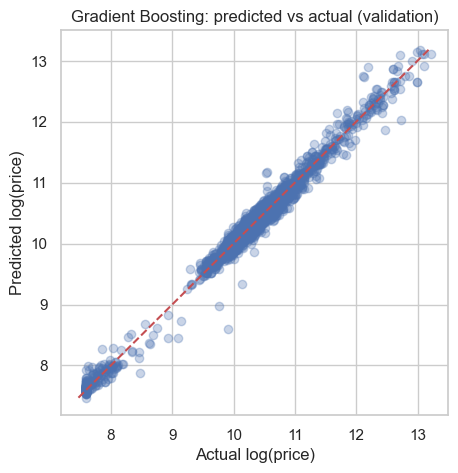

In [25]:
best_pipe = models[best_name]              # fitted on the training set in section 6
pred_val_log = best_pipe.predict(X_val)

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(y_val, pred_val_log, alpha=0.3)
lims = [min(y_val.min(), pred_val_log.min()), max(y_val.max(), pred_val_log.max())]
ax.plot(lims, lims, 'r--')
ax.set_xlabel('Actual log(price)')
ax.set_ylabel('Predicted log(price)')
ax.set_title(f'{best_name}: predicted vs actual (validation)')
plt.show()

In [26]:
errors = X_val[['make', 'model', 'year', 'engine_hp']].assign(
    actual=val.msrp.values,
    predicted=np.expm1(pred_val_log).round(0),
)
errors['abs_error'] = (errors.actual - errors.predicted).abs()
errors.sort_values('abs_error', ascending=False).head(10)

,make,model,year,engine_hp,actual,predicted,abs_error
10421,aston_martin,v12_vantage_s,2016,565.0,198195,397302.0,199107.0
2695,bentley,continental_gt3-r,2015,572.0,337000,166160.0,170840.0
10420,aston_martin,v12_vantage_s,2015,565.0,182395,343880.0,161485.0
10422,aston_martin,v12_vantage_s,2016,565.0,183695,337429.0,153734.0
3318,rolls-royce,dawn,2016,563.0,335000,486187.0,151187.0
2205,porsche,carrera_gt,2005,605.0,440000,309879.0,130121.0
2204,porsche,carrera_gt,2004,605.0,440000,309879.0,130121.0
7039,rolls-royce,park_ward,2001,322.0,259900,141239.0,118661.0
4431,ferrari,ff,2013,651.0,295000,386584.0,91584.0
4433,ferrari,ff,2015,651.0,295000,383808.0,88808.0


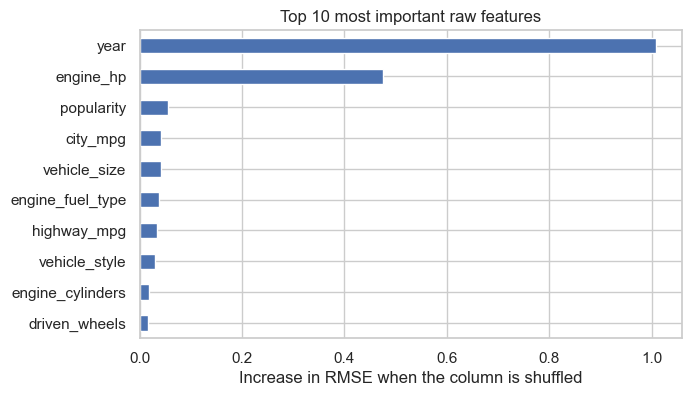

In [27]:
# Permutation importance: how much does the error grow when one raw column is shuffled?
perm = permutation_importance(best_pipe, X_val, y_val, n_repeats=5,
                              random_state=RANDOM_STATE,
                              scoring='neg_root_mean_squared_error')

importance = (pd.Series(perm.importances_mean, index=X_val.columns)
                .sort_values(ascending=False).head(10))

ax = importance.plot.barh(figsize=(7, 4))
ax.invert_yaxis()
ax.set_xlabel('Increase in RMSE when the column is shuffled')
ax.set_title('Top 10 most important raw features')
plt.show()

## 8. Final model and test-set evaluation

The best model (by cross-validation) is re-trained on train + validation and evaluated **once** on the test set.

In [20]:
final_model = clone(models[best_name])
final_model.fit(X_full, y_full)

test_metrics = evaluate(y_test, final_model.predict(X_test))
pd.Series(test_metrics, name=best_name).round(3)

rmse_log             0.109
mae_usd           4361.053
median_ape_pct       6.108
r2_log               0.989
Name: Gradient Boosting, dtype: float64

## 9. Predict the price of a new car

`predict_price` accepts a dictionary with the dataset's column names and returns the price in dollars.

In [28]:
def predict_price(car: dict, model=final_model):
    """car: dict with the dataset columns, e.g. {'make': 'ford', 'year': 2015, 'engine_hp': 300, ...}"""
    row = clean(pd.DataFrame([car]))
    return float(np.expm1(model.predict(row)[0]))


example = X_test.iloc[10].to_dict()
print(example)
print('Predicted: $', round(predict_price(example)))
print('Actual:    $', round(test.msrp.iloc[10]))

{'make': 'ford', 'model': 'ranger', 'year': 2010, 'engine_fuel_type': 'regular_unleaded', 'engine_hp': 207.0, 'engine_cylinders': 6.0, 'transmission_type': 'manual', 'driven_wheels': 'rear_wheel_drive', 'number_of_doors': 2.0, 'market_category': nan, 'vehicle_size': 'compact', 'vehicle_style': 'extended_cab_pickup', 'highway_mpg': 21, 'city_mpg': 15, 'popularity': 5657}
Predicted: $ 22385
Actual:    $ 22155


In [29]:
joblib.dump(final_model, 'car_price_model.joblib')

['car_price_model.joblib']